In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

data_folder = Path(
project_root = Path.cwd().resolve()
while not (project_root / "ml" / "data" / "raw").is_dir():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not find the WasteWise-AI project root.")
    project_root = project_root.parent
data_folder = project_root / "ml" / "data" / "raw"
)

discounts = pd.read_csv(
    data_folder / "discount_scenarios_simulated.csv"
)

print("Discount Dataset Loaded Successfully!")
print("Total Rows:", discounts.shape[0])
print("Total Columns:", discounts.shape[1])

display(discounts.head())


Discount Dataset Loaded Successfully!
Total Rows: 10000
Total Columns: 8


,batch_id,product_id,days_to_expiry,quantity_remaining,discount_pct,estimated_units_sold_simulated,estimated_revenue_simulated,estimated_gross_margin_simulated
0,5001,1006,5,72,0,72,3240.0,1224.0
1,5001,1006,5,72,5,72,3078.0,1062.0
2,5001,1006,5,72,10,72,2916.0,900.0
3,5001,1006,5,72,15,72,2754.0,738.0
4,5001,1006,5,72,20,72,2592.0,576.0


In [2]:

print("Column Names:")
print(discounts.columns.tolist())

print("\nDataset Information:")
discounts.info()

print("\nStatistical Summary:")
display(discounts.describe(include="all"))


Column Names:
['batch_id', 'product_id', 'days_to_expiry', 'quantity_remaining', 'discount_pct', 'estimated_units_sold_simulated', 'estimated_revenue_simulated', 'estimated_gross_margin_simulated']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   batch_id                          10000 non-null  int64  
 1   product_id                        10000 non-null  int64  
 2   days_to_expiry                    10000 non-null  int64  
 3   quantity_remaining                10000 non-null  int64  
 4   discount_pct                      10000 non-null  int64  
 5   estimated_units_sold_simulated    10000 non-null  int64  
 6   estimated_revenue_simulated       10000 non-null  float64
 7   estimated_gross_margin_simulated  10000 non-null  float64
dtypes: float64(2), int64(6)
memory usage: 625.1 KB

S

,batch_id,product_id,days_to_expiry,quantity_remaining,discount_pct,estimated_units_sold_simulated,estimated_revenue_simulated,estimated_gross_margin_simulated
count,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.0000,10000.000000,10000.000000
mean,6000.500000,1005.495500,3.58950,52.778000,10.000000,16.3707,891.936905,227.169005
std,577.379067,2.898072,5.50191,45.456081,7.071421,22.6761,1513.435494,410.970466
min,5001.000000,1001.000000,-2.00000,0.000000,0.000000,0.0000,0.000000,0.000000
25%,5500.750000,1003.000000,0.00000,6.000000,5.000000,0.0000,0.000000,0.000000
50%,6000.500000,1006.000000,2.00000,46.500000,10.000000,0.0000,0.000000,0.000000
75%,6500.250000,1008.000000,5.00000,90.000000,15.000000,30.0000,1224.000000,296.000000
max,7000.000000,1010.000000,30.00000,150.000000,20.000000,102.0000,10440.000000,3654.000000


In [3]:

print("Missing Values:")
print(discounts.isnull().sum())

print("\nMissing Value Percentage:")
print((discounts.isnull().mean() * 100).round(2))


Missing Values:
batch_id                            0
product_id                          0
days_to_expiry                      0
quantity_remaining                  0
discount_pct                        0
estimated_units_sold_simulated      0
estimated_revenue_simulated         0
estimated_gross_margin_simulated    0
dtype: int64

Missing Value Percentage:
batch_id                            0.0
product_id                          0.0
days_to_expiry                      0.0
quantity_remaining                  0.0
discount_pct                        0.0
estimated_units_sold_simulated      0.0
estimated_revenue_simulated         0.0
estimated_gross_margin_simulated    0.0
dtype: float64


In [4]:

print("Duplicate Rows:", discounts.duplicated().sum())

discounts_cleaned = discounts.drop_duplicates().copy()

print("Original Rows:", len(discounts))
print("Cleaned Rows:", len(discounts_cleaned))


Duplicate Rows: 0
Original Rows: 10000
Cleaned Rows: 10000


Numerical Columns:
['batch_id', 'product_id', 'days_to_expiry', 'quantity_remaining', 'discount_pct', 'estimated_units_sold_simulated', 'estimated_revenue_simulated', 'estimated_gross_margin_simulated']


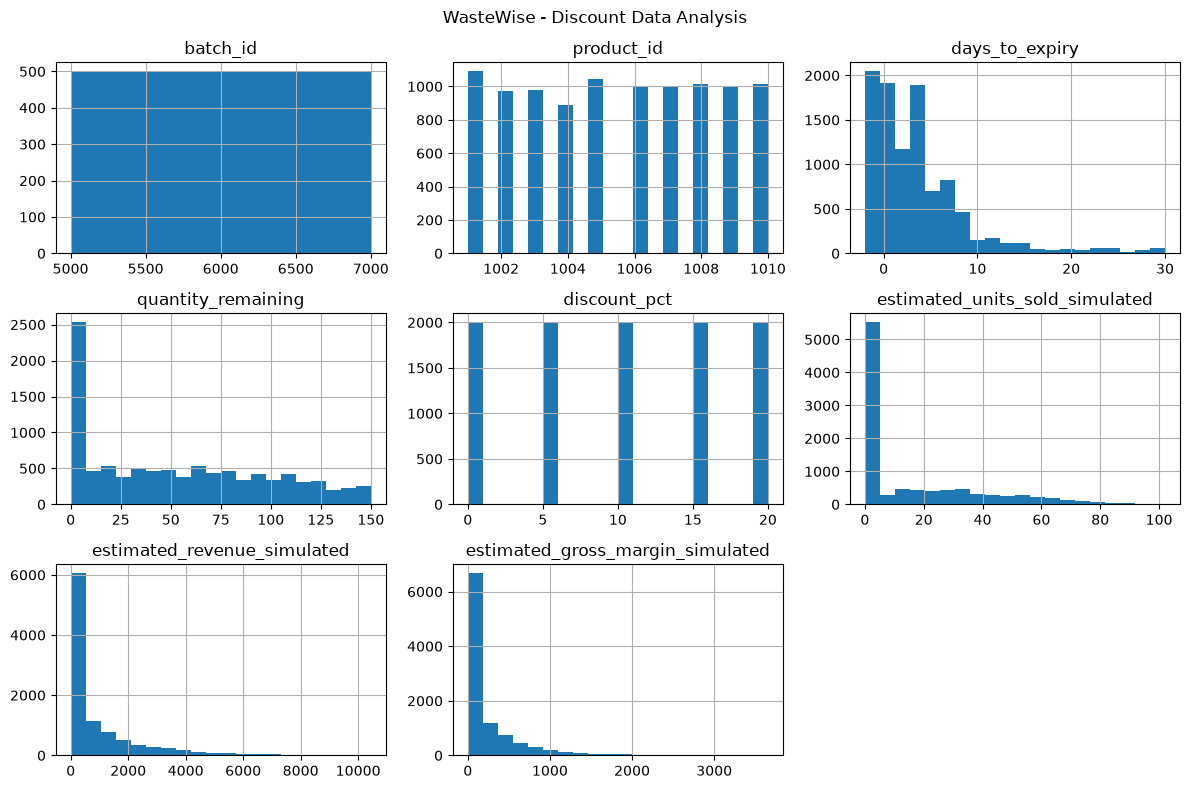

In [5]:

numeric_columns = discounts_cleaned.select_dtypes(
    include=np.number
)

print("Numerical Columns:")
print(numeric_columns.columns.tolist())

if not numeric_columns.empty:
    numeric_columns.hist(
        figsize=(12, 8),
        bins=20
    )

    plt.suptitle("WasteWise - Discount Data Analysis")
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns found.")


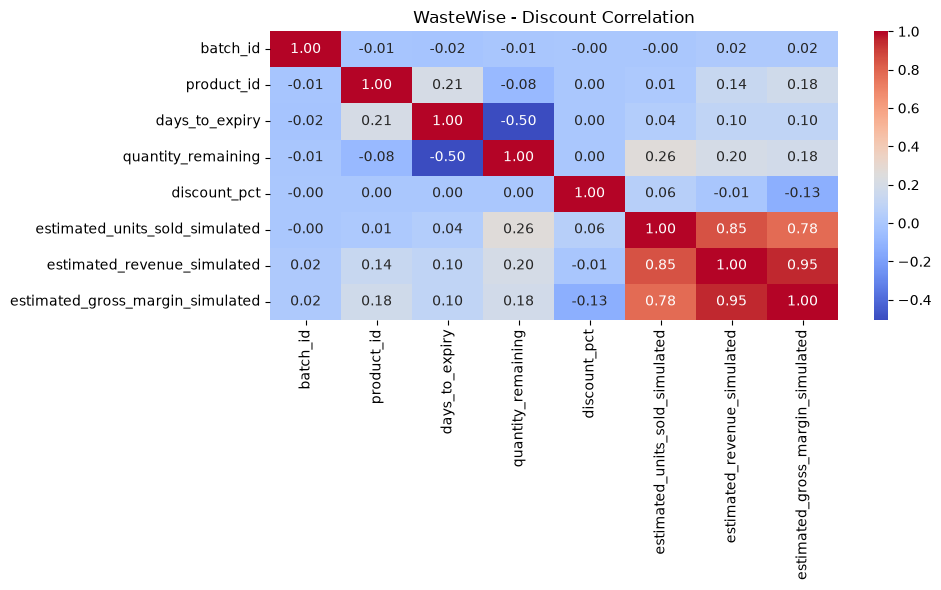

In [6]:

if numeric_columns.shape[1] >= 2:
    plt.figure(figsize=(10, 6))

    sns.heatmap(
        numeric_columns.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("WasteWise - Discount Correlation")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns.")


In [7]:

output_folder = project_root / "ml" / "data" / "processed"

output_folder.mkdir(parents=True, exist_ok=True)

discounts_cleaned.to_csv(
    output_folder / "discounts_cleaned.csv",
    index=False
)

print("Cleaned Discount Dataset Saved Successfully!")


Cleaned Discount Dataset Saved Successfully!


In [8]:

files = {
    "Inventory": "perishable_inventory (1).csv",
    "Batches": "inventory_batches.csv",
    "Products": "products.csv",
    "Discounts": "discount_scenarios_simulated.csv"
}

datasets = {}

for name, filename in files.items():
    df = pd.read_csv(data_folder / filename)
    datasets[name] = df

    print(f"\n{name}: {df.shape}")
    print("Columns:", df.columns.tolist())

print("\nCommon Columns Between Datasets:")

names = list(datasets.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        common = set(datasets[names[i]].columns) & set(
            datasets[names[j]].columns
        )

        print(
            names[i], "&", names[j],
            ":", sorted(common)
        )



Inventory: (1800, 12)
Columns: ['product_id', 'date', 'category', 'opening_stock', 'units_received', 'units_sold', 'unit_price', 'discount_pct', 'days_to_expiry', 'temperature_c', 'waste_units', 'stockout_flag']

Batches: (2000, 16)
Columns: ['batch_id', 'product_id', 'category', 'received_at', 'snapshot_date', 'expiry_date', 'initial_quantity', 'quantity_remaining', 'days_to_expiry', 'avg_daily_sales_7d', 'expected_demand_before_expiry', 'unit_price', 'unit_cost', 'discount_pct', 'expiry_risk_label', 'waste_units_actual_simulated']

Products: (10, 6)
Columns: ['product_id', 'product_name', 'category', 'shelf_life_days', 'selling_price', 'unit_cost']

Discounts: (10000, 8)
Columns: ['batch_id', 'product_id', 'days_to_expiry', 'quantity_remaining', 'discount_pct', 'estimated_units_sold_simulated', 'estimated_revenue_simulated', 'estimated_gross_margin_simulated']

Common Columns Between Datasets:
Inventory & Batches : ['category', 'days_to_expiry', 'discount_pct', 'product_id', 'unit_p